# Human-likeness: how people move, against the models (11/22/26)

Fitting the student to people has used three numbers: solve rate, moves / optimal, and how they change over trials.
Many very different solvers can match those. This notebook compares people with candidate models **move by move**,
on the 70 layouts people played (Olieslagers et al. 2023; 42 participants, every attempt, solved or not), to find
which measures tell the models apart - and so which to fit on.

`experiments/human_profile.py` writes one table, a row per move, for people and for each model (10 runs per layout,
capped at max(50, 10 × optimal), no giving up):

| source | what it is |
|---|---|
| people | every attempt, replayed into boards |
| AND-OR (paper) | Olieslagers et al.'s per-board AND-OR distribution, γ 0.07 (its best fit to people's moves) |
| AND-OR (network) | AND-OR ordered by the start network's dest head, γ 0.07 (the apprentice's teacher) |
| intuition | the start network's policy, temperature 1, 10-board memory (the session student) |
| forward | the forward planner on the start network: K8 D4, λ 16, novelty half-life 80 |
| random | uniform legal moves, 10-board memory |

Per-move measures are pooled over moves, so long attempts weigh more; models never give up, so their long, stuck
attempts weigh more than people's.

In [1]:
import sys
sys.path.insert(0, "..")
import os

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import spearmanr

from rushhour import paths

INK, MUTED, RULE, GRID = "#1f1f1d", "#5f5e5a", "#b5b4ad", "#e6e5e0"
SOURCES = {"people": "#1f1f1d", "AND-OR (paper)": "#2a78d6", "AND-OR (network)": "#08306b", "intuition": "#e6a00d",
           "forward": "#e6550d", "random": "#b5b4ad"}
ROLES = ["red", "depth 1", "depth 2", "depth 3+", "not in tree", "tree too large"]
plt.rcParams.update({"font.size": 9, "axes.titlesize": 10, "axes.titlelocation": "left", "figure.dpi": 110,
                     "legend.frameon": False, "legend.fontsize": 8.5})


def tidy(ax, grid="y"):
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    for side in ("left", "bottom"):
        ax.spines[side].set_color(RULE)
    ax.tick_params(colors=MUTED)
    if grid:
        ax.grid(axis=grid, color=GRID, lw=0.8)
    ax.set_axisbelow(True)


mv = pd.read_csv(os.path.join(paths.MODELS, "summary", "human_profile", "moves.csv.gz"), dtype={"who": str})
mv["source"] = pd.Categorical(mv.source, list(SOURCES))
att = (mv.groupby(["source", "who", "instance", "attempt"], observed=True)
       .agg(moves=("move", "size"), solved=("solved", "first"), optimal=("optimal length", "first"),
            trial=("trial", "first")).reset_index())
att["ratio"] = att.moves / att.optimal
overview = att.groupby("source", observed=True).agg(attempts=("moves", "size"), moves=("moves", "sum"),
                                                     solved=("solved", "mean"))
overview["moves / optimal (solved)"] = att[att.solved].groupby("source", observed=True).ratio.mean()
overview.round(3)

,attempts,moves,solved,moves / optimal (solved)
source,,,,
people,2804,62313,0.703,2.087
AND-OR (paper),700,62957,0.470,5.248
AND-OR (network),700,38853,0.754,2.629
intuition,700,50486,0.636,3.679
forward,700,24789,0.924,2.294
random,700,75700,0.044,7.128


People's solve rate is with giving up and restarts (each restart is a new attempt); the models' is within the cap.

## 1. Which moves: chance of an optimal move by distance to the goal

A move is optimal if it brings the board one move closer to the goal, worse if it moves it further away. Distance 1
(red's path clear) is left out: people finish by dragging red off the board, which isn't recorded as a slide, so
their moves at distance 1 are only the rare ones made instead of finishing.

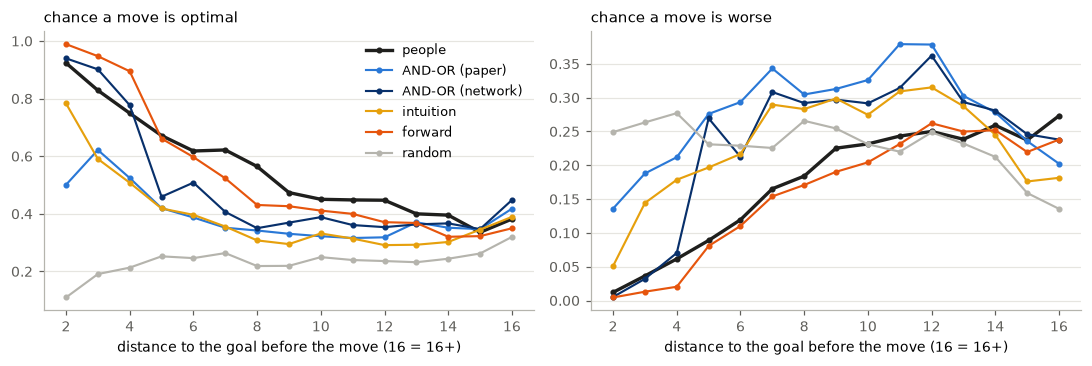

In [2]:
mv["dbin"] = mv.distance.clip(upper=16).where(mv.distance > 1)
fig, axes = plt.subplots(1, 2, figsize=(10, 3.4), sharex=True)
for ax, (name, col) in zip(axes, [("optimal", "optimal"), ("worse", "worse")]):
    for src, color in SOURCES.items():
        d = mv[mv.source == src]
        y = (d.after < d.distance) if col == "optimal" else (d.after > d.distance)
        m = y.groupby(d.dbin).mean()
        ax.plot(m.index, m.values, color=color, lw=2.2 if src == "people" else 1.4, marker="o", ms=3, label=src)
    ax.set_xlabel("distance to the goal before the move (16 = 16+)")
    ax.set_title(f"chance a move is {name}")
    tidy(ax)
axes[0].legend()
plt.tight_layout()
plt.show()

## 2. Where they go: revisits and how long ago

- **board seen**: the move leads to a board already visited in this attempt; **undo**: straight back to the board
  before;
- **placement seen**: the moved car lands where it has already stood in this attempt. Its age - how many moves ago
  that car was last there - is the empirical forgetting curve that a fading novelty memory would have to match.

In [3]:
rev = mv.groupby("source", observed=True)[["board seen", "undo", "placement seen", "new best"]].mean()
rev.round(3)

,board seen,undo,placement seen,new best
source,,,,
people,0.145,0.061,0.489,0.338
AND-OR (paper),0.245,0.052,0.785,0.079
AND-OR (network),0.360,0.159,0.727,0.161
intuition,0.117,0.000,0.751,0.109
forward,0.057,0.000,0.530,0.287
random,0.091,0.000,0.819,0.044


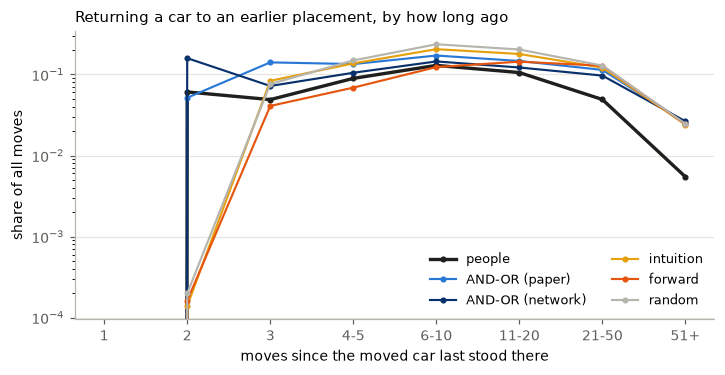

In [4]:
edges = [0, 1, 2, 3, 5, 10, 20, 50, 1000]
labels = ["1", "2", "3", "4-5", "6-10", "11-20", "21-50", "51+"]
fig, ax = plt.subplots(figsize=(7.5, 3.4))
for src, color in SOURCES.items():
    d = mv[mv.source == src]
    share = pd.cut(d["placement age"], edges, labels=labels).value_counts(sort=False) / len(d)
    ax.plot(labels, share.values, color=color, lw=2.2 if src == "people" else 1.4, marker="o", ms=3, label=src)
ax.set_yscale("log")
ax.set_xlabel("moves since the moved car last stood there")
ax.set_ylabel("share of all moves")
ax.set_title("Returning a car to an earlier placement, by how long ago")
ax.legend(ncol=2)
tidy(ax)
plt.show()

## 3. Which cars: the moved car's role in the AND-OR tree

On each board, Olieslagers et al.'s AND-OR tree gives every car a depth: red, its blockers (depth 1), their blockers
(depth 2), and so on; cars in no subgoal are "not in tree". Also: moving the same car twice in a row, and slides
that go as far as they can.

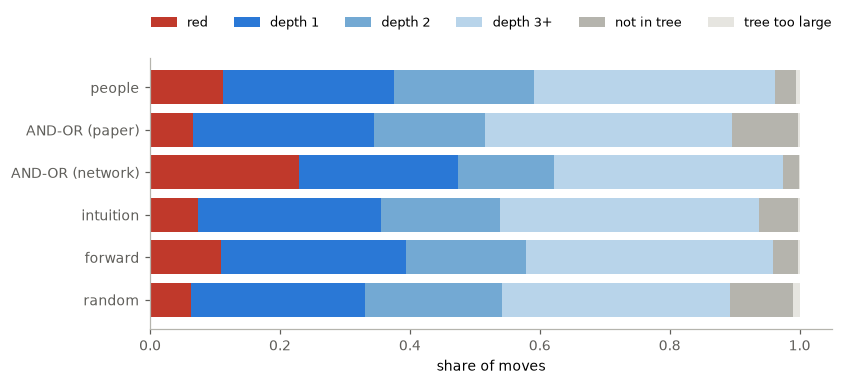

,red,depth 1,depth 2,depth 3+,not in tree,tree too large,same car,full slide,cells per move
source,,,,,,,,,
people,0.112,0.264,0.215,0.371,0.034,0.005,0.079,0.968,1.905
AND-OR (paper),0.066,0.279,0.171,0.380,0.101,0.003,0.118,0.724,1.665
AND-OR (network),0.229,0.245,0.147,0.353,0.024,0.002,0.262,0.747,1.610
intuition,0.074,0.282,0.183,0.399,0.060,0.002,0.124,0.737,1.638
forward,0.110,0.284,0.185,0.381,0.038,0.003,0.123,0.755,1.698
random,0.063,0.268,0.210,0.352,0.097,0.010,0.121,0.681,1.422


In [5]:
roles = pd.crosstab(mv.source, mv.role, normalize="index").reindex(columns=[r for r in ROLES if r in set(mv.role)])
fig, ax = plt.subplots(figsize=(8, 3.2))
left = np.zeros(len(roles))
palette = ["#c0392b", "#2a78d6", "#73a9d3", "#b8d4ea", "#b5b4ad", "#e6e5e0"]
for role, color in zip(roles.columns, palette):
    ax.barh(roles.index.astype(str), roles[role], left=left, color=color, label=role)
    left += roles[role].values
ax.invert_yaxis()
ax.set_xlabel("share of moves")
ax.legend(ncol=6, loc="upper center", bbox_to_anchor=(0.5, 1.2))
tidy(ax, grid=None)
plt.show()
slides = mv.groupby("source", observed=True).agg(**{"same car": ("same car", "mean"),
                                                    "full slide": ("full slide", "mean"),
                                                    "cells per move": ("steps", "mean")})
pd.concat([roles, slides], axis=1).round(3)

## 4. Puzzles: do the models find the same layouts hard?

Per layout: the solve rate, and the median moves / optimal - people's over all their attempts at the puzzle
(`human_data.trials`, unsolved included), the models' with an unsolved run counted at its cap. Spearman correlation
with people across the 70 layouts (people solve between 45% and 100% of each layout).

In [6]:
from rushhour import human_data as hd

tr = hd.trials()
ppl = tr.assign(ratio=tr.moves / tr.distance).groupby("instance").agg(ratio=("ratio", "median"),
                                                                      solved=("solved", "mean"))
rows = {}
for src in list(SOURCES)[1:]:
    m = att[att.source == src].groupby("instance").agg(ratio=("ratio", "median"), solved=("solved", "mean"))
    m = m.reindex(ppl.index)
    rows[src] = {"solve rate (r)": spearmanr(m.solved, ppl.solved).statistic,
                 "median moves / optimal (r)": spearmanr(m.ratio, ppl.ratio).statistic}
pd.DataFrame(rows).T.round(2)

C:\Users\yijos\AppData\Local\Temp\ipykernel_15596\2431353177.py:11: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  "median moves / optimal (r)": spearmanr(m.ratio, ppl.ratio).statistic}


,solve rate (r),median moves / optimal (r)
AND-OR (paper),0.64,0.47
AND-OR (network),0.59,0.53
intuition,0.53,0.45
forward,0.48,0.49
random,0.26,NaN


## 5. People over practice

Every measure by trial (the puzzle's place in the person's order), to see what changes as people gain experience -
what a model of expertise would have to reproduce.

In [7]:
ppl_mv = mv[mv.source == "people"].copy()
ppl_mv["block"] = pd.cut(ppl_mv.trial, [0, 10, 25, 45, 70], labels=["1-10", "11-25", "26-45", "46-70"])
ppl_mv["optimal move"] = ppl_mv.after < ppl_mv.distance
ppl_mv["worse move"] = ppl_mv.after > ppl_mv.distance
ppl_mv["not in tree"] = ppl_mv.role == "not in tree"
ppl_mv["depth 1"] = ppl_mv.role == "depth 1"
cols = ["optimal move", "worse move", "new best", "board seen", "undo", "placement seen", "depth 1", "not in tree",
        "same car", "full slide", "seconds"]
by_block = ppl_mv.groupby("block", observed=True)[cols].agg(lambda x: x.median() if x.name == "seconds" else x.mean())
by_block.round(3)

,optimal move,worse move,new best,board seen,undo,placement seen,depth 1,not in tree,same car,full slide,seconds
block,,,,,,,,,,,
1-10,0.472,0.211,0.292,0.165,0.070,0.529,0.274,0.037,0.091,0.961,0.800
11-25,0.494,0.202,0.321,0.155,0.064,0.505,0.261,0.036,0.084,0.968,0.766
26-45,0.529,0.192,0.366,0.136,0.058,0.467,0.258,0.031,0.075,0.971,0.690
46-70,0.533,0.187,0.374,0.120,0.051,0.453,0.265,0.029,0.065,0.970,0.641


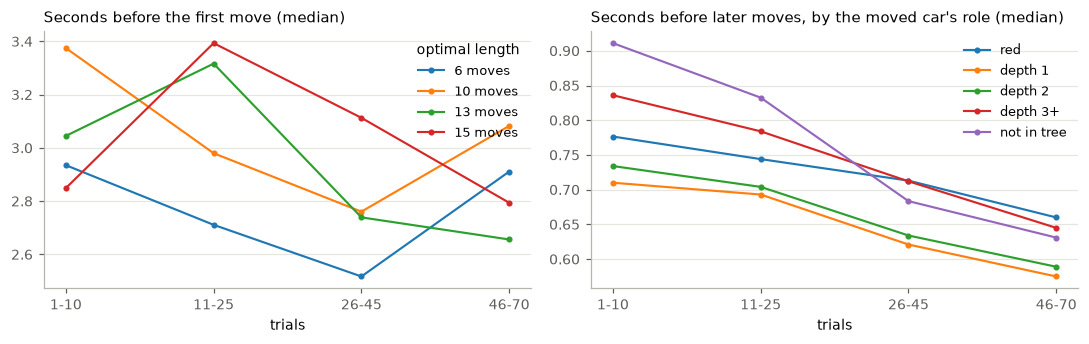

In [8]:
firsts = ppl_mv[ppl_mv.move == 0]
fig, axes = plt.subplots(1, 2, figsize=(10, 3.2))
for L, d in firsts.groupby("optimal length"):
    m = d.groupby("block", observed=True).seconds.median()
    axes[0].plot(m.index.astype(str), m.values, marker="o", ms=3, lw=1.4, label=f"{L} moves")
axes[0].set_title("Seconds before the first move (median)")
axes[0].legend(title="optimal length")
later = ppl_mv[ppl_mv.move > 0]
for role in ["red", "depth 1", "depth 2", "depth 3+", "not in tree"]:
    m = later[later.role == role].groupby("block", observed=True).seconds.median()
    axes[1].plot(m.index.astype(str), m.values, marker="o", ms=3, lw=1.4, label=role)
axes[1].set_title("Seconds before later moves, by the moved car's role (median)")
axes[1].legend()
for ax in axes:
    ax.set_xlabel("trials")
    tidy(ax)
plt.tight_layout()
plt.show()

## 6. Summary: which measures separate the models, and which model is closest

For each scalar measure: people's value, each model's, and the model closest to people.

In [9]:
mv["optimal move"] = mv.after < mv.distance
mv["worse move"] = mv.after > mv.distance
mv["not in tree"] = mv.role == "not in tree"
mv["depth 1"] = mv.role == "depth 1"
mv["red"] = mv.role == "red"
scal = ["optimal move", "worse move", "new best", "board seen", "undo", "placement seen", "red", "depth 1",
        "not in tree", "same car", "full slide"]
tab = mv.groupby("source", observed=True)[scal].mean().T
tab["closest"] = (tab[list(SOURCES)[1:]].sub(tab["people"], axis=0).abs()).idxmin(axis=1)
tab["spread"] = tab[list(SOURCES)[1:]].max(axis=1) - tab[list(SOURCES)[1:]].min(axis=1)
tab.round(3)

source,people,AND-OR (paper),AND-OR (network),intuition,forward,random,closest,spread
optimal move,0.507,0.351,0.415,0.344,0.466,0.242,forward,0.224
worse move,0.198,0.290,0.271,0.252,0.188,0.223,forward,0.102
new best,0.338,0.079,0.161,0.109,0.287,0.044,forward,0.243
board seen,0.145,0.245,0.360,0.117,0.057,0.091,intuition,0.303
undo,0.061,0.052,0.159,0.000,0.000,0.000,AND-OR (paper),0.159
placement seen,0.489,0.785,0.727,0.751,0.530,0.819,forward,0.289
red,0.112,0.066,0.229,0.074,0.110,0.063,forward,0.166
depth 1,0.264,0.279,0.245,0.282,0.284,0.268,random,0.038
not in tree,0.034,0.101,0.024,0.060,0.038,0.097,forward,0.077
same car,0.079,0.118,0.262,0.124,0.123,0.121,AND-OR (paper),0.144


## 7. At matched efficiency

Many measures above track efficiency: a solver that wastes fewer moves makes more optimal moves and more new closest
approaches, whatever its style. To separate style from efficiency, the same measures on solved attempts of 1.5-3 ×
optimal only (mean about 2.0-2.3 for every source; random has a single such attempt).

In [10]:
keys = ["source", "who", "instance", "attempt"]
m = mv.merge(att[keys + ["ratio"]], on=keys)
m = m[(m.ratio >= 1.5) & (m.ratio <= 3) & m.solved]
matched = m.groupby("source", observed=True)[scal].mean().T
first_rows = m.drop_duplicates(keys)
matched.loc["attempts"] = first_rows.groupby("source", observed=True).size()
matched.loc["mean moves / optimal"] = first_rows.groupby("source", observed=True).ratio.mean()
matched.round(3)

source,people,AND-OR (paper),AND-OR (network),intuition,forward,random
optimal move,0.581,0.554,0.614,0.559,0.588,0.583
worse move,0.141,0.128,0.120,0.111,0.097,0.083
new best,0.440,0.426,0.494,0.448,0.492,0.500
board seen,0.097,0.068,0.119,0.006,0.002,0.000
undo,0.056,0.042,0.079,0.000,0.000,0.000
placement seen,0.401,0.291,0.342,0.299,0.251,0.167
red,0.108,0.132,0.192,0.133,0.122,0.167
depth 1,0.271,0.269,0.234,0.258,0.257,0.417
not in tree,0.044,0.196,0.025,0.077,0.043,0.083
same car,0.074,0.092,0.140,0.094,0.111,0.000


## Takeaways

- **Optimal moves and new closest approaches mostly measure efficiency.** Pooled over all moves, the forward planner
  looks closest to people on them, but at matched efficiency every model makes optimal moves at about people's rate
  (0.55-0.61 against 0.58). Profiles by distance to the goal still differ: people stay better than every model in
  the middle of a puzzle (distance 6-9).
- **People revisit and undo; the memory-bound models cannot.** At matched efficiency people return to an earlier board
  on 10% of moves and undo the last move on 6%, like the two AND-OR models (7-12%, 4-8%). The intuition student and
  the forward planner, barred from the last 10 boards, almost never do (0-0.6%). The hard 10-board rule is not
  human; a fading novelty memory, fitted to people's revisits by age, is the natural replacement.
- **People put cars back where they were more than any model** (placement seen 0.40 against 0.25-0.34 at matched
  efficiency): returning a car to an earlier spot is common for them.
- **People rarely move cars outside the AND-OR tree** (3-4%), like the network-ordered AND-OR, the intuition student
  and the forward planner; the paper's AND-OR spreads its lapses over every legal move and moves such cars 10-20% of
  the time.
- **People slide cars as far as they go** (97% of moves, against 72-78% for every model). This may be the interface
  (dragging a car until it stops) rather than planning; worth checking before fitting on it.
- **Puzzle difficulty agrees only moderately** (Spearman 0.45-0.64 across the 70 layouts), best for the two AND-OR
  models on solve rate.
- **Over practice people improve on every measure a little**: more optimal moves (0.47 → 0.53), fewer revisits
  (0.17 → 0.12), fewer undos, less moving the same car twice, and faster moves (0.80 → 0.64 s median), while which
  cars they move stays the same.

Caveats: the models are all the start network or no network, one run of 10 per layout; models never give up; the
role of a car comes from the paper's tree, which models moves of at most 4 cells and caps its size (0.5% of boards
too large).